# AI651 Assignment 3 — Q3: Dataset preparation and graph construction (LargeST, San Diego)
**Student:** Huzaifa | **Roll No:** 25280009 | AI651 Deep Learning for Space, Time and Graphs, Fall 2026, Assignment 3

Run order: this notebook creates every processed file in `data/processed/` that Q4–Q6 use. Raw inputs (from Kaggle `liuxu77/largest`) must be in `data/raw/`: `ca_meta.csv`, `ca_rn_adj.npy`, `ca_his_raw_2020.h5`, `ca_his_raw_2021.h5`.

In [1]:
import os, sys, json, time, pathlib
sys.path.insert(0, '../src')
import numpy as np, pandas as pd, h5py
import matplotlib; import matplotlib.pyplot as plt, matplotlib.dates as mdates
from common import set_seed, RAW, PROC, RES, FIG, save_json, SEED
set_seed(SEED); print('Global seed =', SEED)
R = {}                      # everything quoted in the report is saved to results/q3_results.json
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .3})

/home/huzaifa/miniconda3/envs/pa1/lib/python3.11/site-packages/torch/cuda/__init__.py:58: FutureWarning: The pynvml package is deprecated. Please install nvidia-ml-py instead. If you did not install pynvml directly, please report this to the maintainers of the package that installed pynvml for you.
  import pynvml  # type: ignore[import]


Global seed = 42


## Q3(a)-1  Extract all 716 San Diego sensors
The Kaggle release only contains the full California files. As in the official LargeST notebook `data/sd/generate_sd_dataset.ipynb`, San Diego = sensors with `District == 11`; their rows in the adjacency matrix are given by the meta column `ID2`, and their flow columns are the string sensor `ID`s.

In [2]:
meta = pd.read_csv(f'{RAW}/ca_meta.csv')
sd_meta = meta[meta.District == 11].reset_index(drop=True)
assert len(sd_meta) == 716 and (sd_meta.County == 'San Diego').all()
assert (meta.ID2.values == np.arange(len(meta))).all()               # ID2 == row index in the CA adjacency
sensor_ids = sd_meta.ID.astype(str).tolist()
print('San Diego sensors:', len(sensor_ids), '| counties:', sd_meta.County.unique().tolist(), '| freeways:', sd_meta.Fwy.nunique())
sd_meta.to_csv(f'{PROC}/sd_meta.csv', index=False)
np.save(f'{PROC}/sd_sensor_ids.npy', np.array(sensor_ids))
sd_meta.head()

San Diego sensors: 716 | counties: ['San Diego'] | freeways: 26


,ID,Lat,Lng,District,County,Fwy,Lanes,Type,Direction,ID2
0,1114091,32.544463,-117.032486,11,San Diego,I5-N,6,Mainline,N,6931
1,1118333,32.551690,-117.045725,11,San Diego,I5-N,4,Mainline,N,6932
2,1118348,32.558459,-117.061845,11,San Diego,I5-N,4,Mainline,N,6933
3,1114720,32.561334,-117.067081,11,San Diego,I5-N,4,Mainline,N,6934
4,1118352,32.569052,-117.076507,11,San Diego,I5-N,4,Mainline,N,6935


In [3]:
def extract_year(year):
    """Read only the 716 SD columns of the (T x 8600) pandas-fixed-format HDF5 file; cache as float32."""
    out = f'{PROC}/sd_raw_5min_{year}.npy'; tsf = f'{PROC}/sd_raw_5min_{year}_ts.npy'
    if os.path.exists(out) and os.path.exists(tsf):
        return np.load(out), pd.DatetimeIndex(np.load(tsf))
    t0 = time.time()
    with h5py.File(f'{RAW}/ca_his_raw_{year}.h5', 'r') as f:
        g = f['t']
        ids = [x.decode() for x in g['axis0'][:]]
        assert ids == [x.decode() for x in g['block0_items'][:]]
        pos = {k: i for i, k in enumerate(ids)}
        cols = np.array([pos[s] for s in sensor_ids])               # column of every SD sensor, in meta order
        order = np.argsort(cols); sc = cols[order]
        V = g['block0_values']; ts = pd.to_datetime(g['axis1'][:])
        arr = np.empty((V.shape[0], len(cols)), np.float32)
        for a in range(0, V.shape[0], 8784):
            arr[a:a + 8784][:, order] = V[a:a + 8784, :][:, sc]
    np.save(out, arr); np.save(tsf, ts.values)
    print(f'  extracted {year} in {time.time()-t0:.0f}s')
    return arr, ts

parts = {y: extract_year(y) for y in (2020, 2021)}
for y, (a, ts) in parts.items():
    print(y, a.shape, ts[0], '->', ts[-1], '| step', pd.Series(ts).diff().dropna().unique())

2020 (105408, 716) 2020-01-01 00:00:00 -> 2020-12-31 23:55:00 | step <TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[ns]
2021 (105120, 716) 2021-01-01 00:00:00 -> 2021-12-31 23:55:00 | step <TimedeltaArray>
['0 days 00:05:00']
Length: 1, dtype: timedelta64[ns]


## Q3(a)-2  Keep 2020 and 2021 only
We only ever load the 2020 and 2021 files, concatenated in time order.

In [4]:
X5 = np.concatenate([parts[2020][0], parts[2021][0]]); ts5 = parts[2020][1].append(parts[2021][1])
assert ts5.is_monotonic_increasing and ts5.is_unique and set(ts5.year) == {2020, 2021}
assert (np.diff(ts5.values).astype('timedelta64[m]') == np.timedelta64(5, 'm')).all()          # no gaps in the 5-min grid
print('5-min tensor:', X5.shape, ts5[0], '->', ts5[-1], '| expected rows 366*288 + 365*288 =', 366*288 + 365*288)
assert X5.shape[0] == 366*288 + 365*288

5-min tensor: (210528, 716) 2020-01-01 00:00:00 -> 2021-12-31 23:55:00 | expected rows 366*288 + 365*288 = 210528


## Q3(a) SUM vs MEAN — what is the LargeST flow variable?
PeMS 5-minute station flow is the **number of vehicles that crossed the detector station during the 5-minute interval** (vehicles / 5 min), summed over lanes — a *count*, not an hourly rate. We confirm this from the data itself:
* every reading is a non-negative **integer**;
* if the readings were hourly rates extrapolated from 5-minute counts they would all be multiples of 12 (12 × count); the fraction of readings divisible by 12 is ≈ 1/12, which is what integer counts give.

**Decision: SUM.** 15-min flow = Σ of the three 5-min counts = vehicles per 15 min. A mean would silently change the unit to "vehicles per 5 min, averaged" (a 3× smaller number that no longer is the physical total of the interval). Note that the official LargeST helper notebook uses `.resample('15T').mean().round(0)`; the assignment instead requires units be preserved, so we sum. (Consequence: our numbers are 3× the official LargeST scale.)

In [5]:
v = X5[~np.isnan(X5)]
frac_int = float(np.mean(v == np.round(v))); frac_12 = float(np.mean(v % 12 == 0))
print(f'integer-valued: {frac_int:.4f} | divisible by 12: {frac_12:.4f} (counts -> ~{1/12:.4f}; hourly rates from counts -> 1.0)')
print('5-min value quantiles [0,1,50,90,99,99.9,100]%:', np.quantile(v, [0, .01, .5, .9, .99, .999, 1]))
print('readings equal to 999:', int((X5 == 999).sum()), '(possible upper cap; kept)')
R['flow_units'] = dict(frac_integer=frac_int, frac_div12=frac_12, expected_if_counts=1/12, aggregation='SUM of 3 five-minute counts -> vehicles per 15 min')
assert frac_int == 1.0 and abs(frac_12 - 1/12) < 0.01

integer-valued: 1.0000 | divisible by 12: 0.0858 (counts -> ~0.0833; hourly rates from counts -> 1.0)


5-min value quantiles [0,1,50,90,99,99.9,100]%: [  0.   5. 182. 461. 681. 827. 999.]
readings equal to 999: 155 (possible upper cap; kept)


## Q3(a)-4  Missing values: detection
Three kinds of problems are measured **per sensor and overall** on the raw 5-min data:
1. **NaN** — explicit missing readings.
2. **Zeros.** A single 0 on a mainline freeway sensor at night can be a genuine empty interval (zero rate by hour of day is largest 00–04h and ≈0.04 % mid-day); long runs of zeros are a dead sensor.
3. **Flat-lines (stuck values):** many consecutive *identical* non-zero readings.

Rule used for (2)+(3): a run of **≥ 36 consecutive identical readings (≥ 3 hours; includes runs of zeros)** is treated as a sensor outage → set to missing. Shorter runs of zeros or equal values are kept (they are plausible for low-volume sensors). Runs are detected **within each split segment** (2020 | Jan–Mar 2021 | Apr–Dec 2021), so no run ever spans a split boundary and nothing learned from a later split influences an earlier one.

In [6]:
STUCK_LEN = 36   # 5-min steps = 3 h
b_val = int(np.searchsorted(ts5, pd.Timestamp('2021-01-01'))); b_test = int(np.searchsorted(ts5, pd.Timestamp('2021-04-01')))
segs5 = [(0, b_val), (b_val, b_test), (b_test, len(ts5))]
print('5-min split segments:', segs5)

def stuck_runs(col, minlen):
    """Boolean mask of entries inside runs of >= minlen identical non-NaN values."""
    n = len(col); same = np.r_[False, col[1:] == col[:-1]]           # NaN == NaN is False -> breaks runs
    start = np.flatnonzero(~same); lens = np.diff(np.r_[start, n])
    m = np.zeros(n, bool)
    for s, l in zip(start[lens >= minlen], lens[lens >= minlen]): m[s:s + l] = True
    return m

nan_raw = np.isnan(X5)
zero_raw = (X5 == 0)
stuck = np.zeros_like(nan_raw)
for a, b in segs5:
    for j in range(X5.shape[1]):
        stuck[a:b, j] = stuck_runs(X5[a:b, j], STUCK_LEN)
stuck_zero = stuck & zero_raw; stuck_pos = stuck & ~zero_raw
bad5 = nan_raw | stuck                                              # entries treated as missing at 5-min level
tot = X5.size
ov = dict(total_readings=int(tot), nan=int(nan_raw.sum()), zeros_total=int(zero_raw.sum()), stuck_zero=int(stuck_zero.sum()),
          stuck_positive=int(stuck_pos.sum()), missing_5min=int(bad5.sum()))
for k in ('nan', 'zeros_total', 'stuck_zero', 'stuck_positive', 'missing_5min'): ov[k + '_pct'] = 100 * ov[k] / tot
print(json.dumps({k: (round(x, 4) if isinstance(x, float) else x) for k, x in ov.items()}, indent=1))
R['missing_overall_5min'] = ov
print('sensors entirely NaN over 2020-21:', int(nan_raw.all(0).sum()), '| sensors with >50% missing_5min:', int((bad5.mean(0) > .5).sum()),
      '| sensors with 0% missing:', int((bad5.mean(0) == 0).sum()))

5-min split segments: [(0, 105408), (105408, 131328), (131328, 210528)]


{
 "total_readings": 150738048,
 "nan": 7636666,
 "zeros_total": 402018,
 "stuck_zero": 85685,
 "stuck_positive": 19502,
 "missing_5min": 7741853,
 "nan_pct": 5.0662,
 "zeros_total_pct": 0.2667,
 "stuck_zero_pct": 0.0568,
 "stuck_positive_pct": 0.0129,
 "missing_5min_pct": 5.136
}
sensors entirely NaN over 2020-21: 19 | sensors with >50% missing_5min: 43 | sensors with 0% missing: 0


### Per-sensor report (saved to `results/q3_missing_per_sensor.csv`) and figures

      nan_pct  zero_pct  stuck_zero_pct  stuck_positive_pct  missing_5min_pct  missing_5min_pct_2020  missing_5min_pct_2021
mean    5.066     0.267           0.057               0.013             5.136                  4.178                  6.097
50%     0.013     0.007           0.000               0.000             0.013                  0.014                  0.012
max   100.000    30.920          21.333               3.691           100.000                100.000                100.000

worst sensors:
 sensor_id  nan_pct  zero_pct  stuck_zero_pct  stuck_positive_pct  missing_5min_pct  missing_5min_pct_2020  missing_5min_pct_2021
  1118458    100.0       0.0             0.0                 0.0             100.0                  100.0                  100.0
  1108323    100.0       0.0             0.0                 0.0             100.0                  100.0                  100.0
  1123087    100.0       0.0             0.0                 0.0             100.0                  

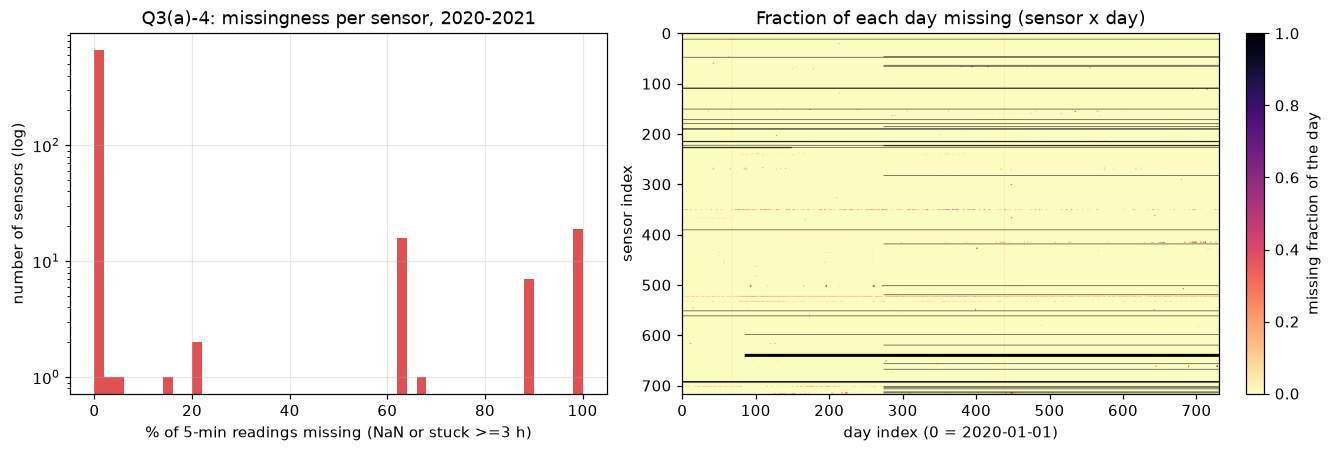

In [7]:
yr = ts5.year.values
rows = pd.DataFrame({'sensor_id': sensor_ids})
rows['nan_pct'] = 100 * nan_raw.mean(0); rows['zero_pct'] = 100 * zero_raw.mean(0)
rows['stuck_zero_pct'] = 100 * stuck_zero.mean(0); rows['stuck_positive_pct'] = 100 * stuck_pos.mean(0)
rows['missing_5min_pct'] = 100 * bad5.mean(0)
for y in (2020, 2021): rows[f'missing_5min_pct_{y}'] = 100 * bad5[yr == y].mean(0)
rows.to_csv(f'{RES}/q3_missing_per_sensor.csv', index=False)
print(rows.describe().loc[['mean', '50%', 'max']].round(3).to_string())
worst = rows.sort_values('missing_5min_pct', ascending=False).head(5); print('\nworst sensors:\n', worst.round(2).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
ax[0].hist(rows.missing_5min_pct, bins=50, color='tab:red', alpha=.8); ax[0].set_yscale('log')
ax[0].set_xlabel('% of 5-min readings missing (NaN or stuck >=3 h)'); ax[0].set_ylabel('number of sensors (log)'); ax[0].set_title('Q3(a)-4: missingness per sensor, 2020-2021')
day = (ts5.normalize() - ts5[0].normalize()).days.values
D = np.zeros((day.max() + 1, 716), np.float32); np.add.at(D, day, bad5); D /= 288
im = ax[1].imshow(D.T, aspect='auto', cmap='magma_r', vmin=0, vmax=1, extent=[0, day.max() + 1, 716, 0])
ax[1].set_xlabel('day index (0 = 2020-01-01)'); ax[1].set_ylabel('sensor index'); ax[1].set_title('Fraction of each day missing (sensor x day)'); ax[1].grid(False)
fig.colorbar(im, ax=ax[1], label='missing fraction of the day'); fig.savefig(f'{FIG}/q3a_missingness.png', dpi=160); plt.show()

### Q3(a)-4  Daylight-saving time check
The timestamps are a regular 5-minute grid. Is that grid in *local wall-clock* time or in fixed standard time, and what does daylight-saving time (DST) do to the data? Check (i) whether the rush-hour timing is the same in winter and summer (wall-clock ⇒ unchanged; fixed standard time ⇒ shifts by one hour) and (ii) what the data look like on the DST transition days (spring forward: 8 Mar 2020 and 14 Mar 2021; fall back: 1 Nov 2020 and 7 Nov 2021).

In [8]:
good = np.where(bad5.mean(0) < 0.05)[0]                                     # sensors that are almost always observed
tot_ = np.nanmean(np.where(bad5[:, good], np.nan, X5[:, good]), axis=1)    # network-mean 5-min flow
slot5 = ts5.hour.values * 12 + ts5.minute.values // 5; wk = ts5.dayofweek.values < 5
def rise_hour(a, b):
    m = wk & (ts5 >= a) & (ts5 < b); prof = np.array([np.nanmean(tot_[m & (slot5 == k)]) for k in range(288)])
    seg = prof[48:120]; return float((48 + np.argmax(seg > 0.5 * seg.max())) / 12), float((48 + np.argmax(seg)) / 12)     # 4h..10h window
r_w, pk_w = rise_hour('2021-01-04', '2021-03-01'); r_s, pk_s = rise_hour('2021-07-05', '2021-09-01')
dst = dict(morning_rise_hour_winter=r_w, morning_peak_hour_winter=pk_w, morning_rise_hour_summer=r_s, morning_peak_hour_summer=pk_s, days={})
for kind, d, hr in (('spring-forward', '2020-03-08', 2), ('spring-forward', '2021-03-14', 2), ('fall-back', '2020-11-01', 1), ('fall-back', '2021-11-07', 1)):
    i0 = int(np.searchsorted(ts5, pd.Timestamp(d))); day = nan_raw[i0:i0 + 288][:, good]                       # NaN (not the stuck-run flag) fraction per hour
    per_hour = day.reshape(24, 12, -1).mean((1, 2)); others = np.delete(per_hour, hr)
    dst['days'][d] = dict(kind=kind, hour=hr, nan_frac_in_hour=float(per_hour[hr]), nan_frac_other_hours_mean=float(others.mean()), steps_in_day=int(day.shape[0]))
print(json.dumps(dst, indent=1))
R['dst'] = dst

{
 "morning_rise_hour_winter": 5.583333333333333,
 "morning_peak_hour_winter": 7.75,
 "morning_rise_hour_summer": 5.5,
 "morning_peak_hour_summer": 7.75,
 "days": {
  "2020-03-08": {
   "kind": "spring-forward",
   "hour": 2,
   "nan_frac_in_hour": 1.0,
   "nan_frac_other_hours_mean": 0.0018170019467878002,
   "steps_in_day": 288
  },
  "2021-03-14": {
   "kind": "spring-forward",
   "hour": 2,
   "nan_frac_in_hour": 1.0,
   "nan_frac_other_hours_mean": 0.0,
   "steps_in_day": 288
  },
  "2020-11-01": {
   "kind": "fall-back",
   "hour": 1,
   "nan_frac_in_hour": 0.009950248756218905,
   "nan_frac_other_hours_mean": 5.407743889249405e-06,
   "steps_in_day": 288
  },
  "2021-11-07": {
   "kind": "fall-back",
   "hour": 1,
   "nan_frac_in_hour": 0.008582089552238806,
   "nan_frac_other_hours_mean": 2.163097555699762e-05,
   "steps_in_day": 288
  }
 }
}


/tmp/ipykernel_102965/3053893659.py:2: RuntimeWarning: Mean of empty slice
  tot_ = np.nanmean(np.where(bad5[:, good], np.nan, X5[:, good]), axis=1)    # network-mean 5-min flow


## Q3(a)-3  Resample 5 min → 15 min (SUM, NaN-aware)
$X^{15}_t=\sum_{k=0}^{2}X^{5}_{3t+k}$ (vehicles per 15 min), computed on the bad-value-masked 5-min series. **NaN-aware rule:** if all 3 readings are valid → plain sum; if exactly 2 are valid → their sum × 3/2 (unbiased scaling that keeps units = vehicles per 15 min); if ≤ 1 valid → the 15-min value is **missing (NaN)**. Bins are left-labelled (00:00, 00:15, …) and, because the grid starts at 00:00 and has no gaps, bin $t$ is exactly rows $3t..3t+2$.

In [9]:
X5m = np.where(bad5, np.nan, X5).astype(np.float32)
T5 = X5m.shape[0]; assert T5 % 3 == 0
G = X5m.reshape(T5 // 3, 3, -1)
cnt = (~np.isnan(G)).sum(1); ssum = np.nansum(G, axis=1)
X15 = np.where(cnt >= 2, ssum * 3.0 / np.maximum(cnt, 1), np.nan).astype(np.float32)
ts15 = ts5[::3]; assert len(ts15) == X15.shape[0] == 70176
assert (np.diff(ts15.values).astype('timedelta64[m]') == np.timedelta64(15, 'm')).all()
print('15-min tensor', X15.shape, ts15[0], '->', ts15[-1], '(expected 366*96 + 365*96 = 70176)')
print('bins with 3/3, 2/3, <=1/3 valid:', [int((cnt == c).sum()) for c in (3,)], int((cnt == 2).sum()), int((cnt <= 1).sum()))
# --- verification against pandas (complete bins only) and the assignment formula
j = int(np.nanargmax((cnt == 3).sum(0)))
pd_sum = pd.Series(X5m[:, j], index=ts5).resample('15min', label='left', closed='left').sum(min_count=3)
ok = ~np.isnan(pd_sum.values); assert np.allclose(pd_sum.values[ok], X15[:, j][ok]); assert np.allclose(X15[:, j][cnt[:, j] == 3], G[:, :, j].sum(1)[cnt[:, j] == 3])
print('verified against pandas resample(15min).sum(min_count=3) and sum_k X5[3t+k] on sensor', sensor_ids[j])
R['resample'] = dict(rule='sum of 3 five-minute counts, NaN-aware (2/3 valid -> x3/2, <=1 valid -> NaN)', T15=int(X15.shape[0]),
                     bins_full=int((cnt == 3).sum()), bins_two=int((cnt == 2).sum()), bins_missing=int((cnt <= 1).sum()),
                     missing_15min_pct=float(100 * np.isnan(X15).mean()))
print('missing 15-min entries: %.3f %% of %d' % (R['resample']['missing_15min_pct'], X15.size))

15-min tensor (70176, 716) 2020-01-01 00:00:00 -> 2021-12-31 23:45:00 (expected 366*96 + 365*96 = 70176)
bins with 3/3, 2/3, <=1/3 valid: [47659704] 6914 2579398


verified against pandas resample(15min).sum(min_count=3) and sum_k X5[3t+k] on sensor 1108717
missing 15-min entries: 5.134 % of 50246016


## Q3(a)-4  Missing values: handling policy (no leakage)
1. 5-min NaN and ≥3 h stuck runs → missing (above); 15-min bins with ≤1 valid reading → missing.
2. **Targets / metrics:** only entries that are genuinely *observed* (valid mask = not missing) are used in the loss and in MAE/RMSE. Imputed values are never used as targets, so a model cannot be rewarded for reproducing an imputation.
3. **Model inputs** need a number everywhere: (i) **causal forward-fill** from the last observed value, at most **4 steps (1 h)**, applied **separately inside each split** (2020 | Jan–Mar 2021 | Apr–Dec 2021) so no information crosses split boundaries and no future value is ever used; (ii) anything still missing → the **per-sensor mean of the TRAINING split (2020) observed values** (global training mean for sensors with no 2020 observation). No val/test statistic is used anywhere.
4. All 716 sensors are kept (the graph needs all nodes); heavily-missing sensors are simply masked out of loss/metrics where unobserved.

In [10]:
b15 = [b // 3 for b in (0, b_val, b_test, T5)]
segs15 = [(b15[0], b15[1]), (b15[1], b15[2]), (b15[2], b15[3])]; names = ['train(2020)', 'val(Jan-Mar 2021)', 'test(Apr-Dec 2021)']
valid = ~np.isnan(X15)
filled = X15.copy(); n_ff = 0
for a, b in segs15:
    seg = pd.DataFrame(X15[a:b]).ffill(limit=4).values
    n_ff += int((np.isnan(X15[a:b]) & ~np.isnan(seg)).sum()); filled[a:b] = seg
tr0, tr1 = segs15[0]
sensor_train_mean = np.nanmean(X15[tr0:tr1], axis=0)                        # training split only
glob_train_mean = float(np.nanmean(X15[tr0:tr1]))
no_train_obs = np.isnan(sensor_train_mean); sensor_train_mean = np.where(no_train_obs, glob_train_mean, sensor_train_mean)
n_mean = int(np.isnan(filled).sum()); filled = np.where(np.isnan(filled), sensor_train_mean[None, :], filled).astype(np.float32)
assert not np.isnan(filled).any() and (filled[valid] == X15[valid]).all()
fills = dict(observed=int(valid.sum()), forward_filled=n_ff, train_mean_filled=n_mean, total=int(valid.size),
             sensors_without_2020_obs=int(no_train_obs.sum()), global_train_mean=glob_train_mean)
for k in ('observed', 'forward_filled', 'train_mean_filled'): fills[k + '_pct'] = 100 * fills[k] / fills['total']
per_split = {nm: dict(rows=b - a, valid_pct=float(100 * valid[a:b].mean())) for nm, (a, b) in zip(names, segs15)}
print(json.dumps(fills, indent=1)); print(per_split)
R['imputation'] = fills; R['valid_pct_per_split'] = per_split

np.save(f'{PROC}/sd_flow_15min_raw.npy', X15[..., None])                    # NaN = missing  (T,716,1)
np.save(f'{PROC}/sd_flow_15min_filled.npy', filled[..., None])              # (T,716,1)  model input tensor X
np.save(f'{PROC}/sd_valid_mask.npy', valid)                                 # (T,716) True = observed
np.save(f'{PROC}/sd_timestamps.npy', ts15.values)
print('saved X in R^{T x N x F}:', filled[..., None].shape, 'dtype', filled.dtype)

/tmp/ipykernel_102965/405394510.py:9: RuntimeWarning: Mean of empty slice
  sensor_train_mean = np.nanmean(X15[tr0:tr1], axis=0)                        # training split only


{
 "observed": 47666618,
 "forward_filled": 15505,
 "train_mean_filled": 2563893,
 "total": 50246016,
 "sensors_without_2020_obs": 19,
 "global_train_mean": 607.7505493164062,
 "observed_pct": 94.86646264651112,
 "forward_filled_pct": 0.030858167939125762,
 "train_mean_filled_pct": 5.102679185549756
}
{'train(2020)': {'rows': 35136, 'valid_pct': 95.82478315703514}, 'val(Jan-Mar 2021)': {'rows': 8640, 'valid_pct': 93.84386962031864}, 'test(Apr-Dec 2021)': {'rows': 26400, 'valid_pct': 93.92569197562214}}


saved X in R^{T x N x F}: (70176, 716, 1) dtype float32


## Q3(a)-5  Three sensors over one week
A normal pre-COVID week (Mon 3 Feb – Sun 9 Feb 2020) with complete data; the three sensors are chosen automatically as the 10th / 50th / 90th percentile of mean flow among sensors that are 100 % observed that week.

candidate sensors fully observed that week: 687 | picked ['1125737', '1108665', '1108711']


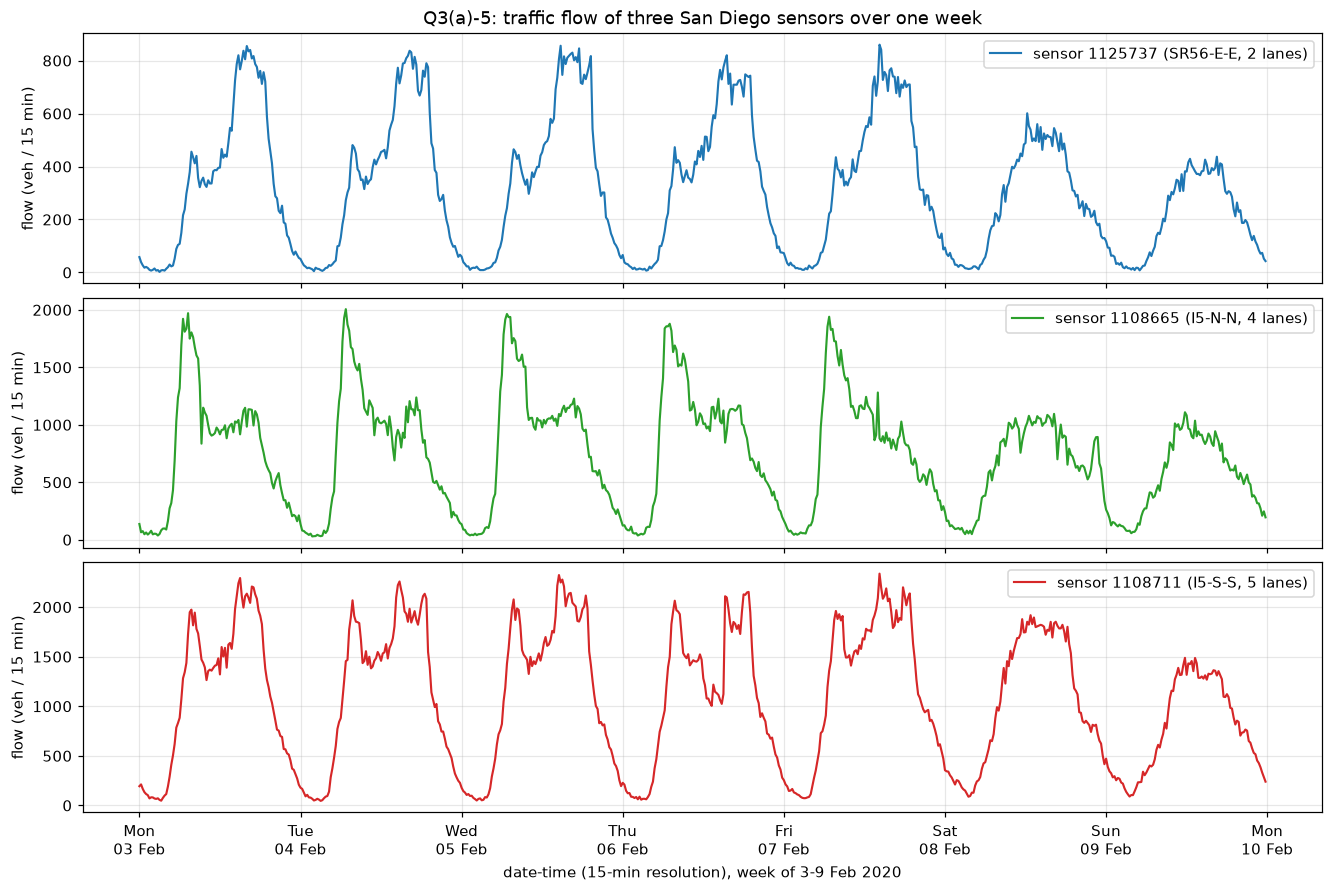

In [11]:
w0, w1 = pd.Timestamp('2020-02-03'), pd.Timestamp('2020-02-10')
wm = (ts15 >= w0) & (ts15 < w1)
complete = valid[wm].all(0); cand = np.where(complete)[0]
mf = X15[wm][:, cand].mean(0); order = np.argsort(mf)
pick = [cand[order[int(q * (len(cand) - 1))]] for q in (.1, .5, .9)]
print('candidate sensors fully observed that week:', len(cand), '| picked', [sensor_ids[p] for p in pick])
fig, axs = plt.subplots(3, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, p, c in zip(axs, pick, ('tab:blue', 'tab:green', 'tab:red')):
    ax.plot(ts15[wm], X15[wm][:, p], color=c, lw=1.4, label=f'sensor {sensor_ids[p]} ({sd_meta.Fwy[p]}-{sd_meta.Direction[p]}, {sd_meta.Lanes[p]} lanes)')
    ax.set_ylabel('flow (veh / 15 min)'); ax.legend(loc='upper right')
axs[-1].xaxis.set_major_locator(mdates.DayLocator()); axs[-1].xaxis.set_major_formatter(mdates.DateFormatter('%a\n%d %b'))
axs[-1].set_xlabel('date-time (15-min resolution), week of 3-9 Feb 2020')
axs[0].set_title('Q3(a)-5: traffic flow of three San Diego sensors over one week')
fig.savefig(f'{FIG}/q3a_three_sensors_week.png', dpi=160); plt.show()
R['week_plot'] = dict(week='2020-02-03..2020-02-09', sensors=[sensor_ids[p] for p in pick], n_candidates=int(len(cand)))

## Q3(b)  The road-distance adjacency
Extract $A_{SD}=A_{CA}[ID2][:,ID2]$ and **assert** that its row/column order equals the order of the traffic tensor columns (both are the order of `sd_meta`).

In [12]:
A_ca = np.load(f'{RAW}/ca_rn_adj.npy', mmap_mode='r')
ID2 = sd_meta.ID2.values
A = np.asarray(A_ca[ID2][:, ID2], dtype=np.float64)
tensor_ids = np.load(f'{PROC}/sd_sensor_ids.npy').tolist()                  # column order of the saved traffic tensor
with h5py.File(f'{RAW}/ca_his_raw_2020.h5', 'r') as f:
    h5_ids = [x.decode() for x in f['t/axis0'][:]]
# ordering assertions: meta == traffic-tensor order; adjacency rows are meta rows ID2; every SD id is a column of the h5 file
assert tensor_ids == sd_meta.ID.astype(str).tolist() == [str(meta.ID.iloc[i]) for i in ID2]
assert all(s in set(h5_ids) for s in tensor_ids) and A.shape == (716, 716) == (filled.shape[1],) * 2
print('ordering OK: adjacency rows/cols == meta rows == traffic tensor columns (716 sensors)')
np.save(f'{PROC}/sd_adj.npy', A)

# independent sanity check of the ordering: road-network weights must decay with GEOGRAPHIC distance
def haversine(lat1, lon1, lat2, lon2):
    p = np.pi / 180; a = np.sin((lat2 - lat1) * p / 2)**2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2)**2
    return 12742 * np.arcsin(np.sqrt(a))
lat, lng = sd_meta.Lat.values, sd_meta.Lng.values
DIST = haversine(lat[:, None], lng[None, :], lat[None, :], lng[None, :])    # (716,716) km
off = A.copy(); np.fill_diagonal(off, 0); E = off > 0
d_edge = DIST[E]; d_all = DIST[~np.eye(716, dtype=bool)]
print('median geographic distance: connected pairs %.2f km vs all pairs %.2f km' % (np.median(d_edge), np.median(d_all)))
assert np.median(d_edge) < 0.2 * np.median(d_all)
shuffle = np.random.default_rng(SEED).permutation(716); Eperm = (off[shuffle][:, shuffle]) > 0
print('(if the order were wrong, e.g. shuffled rows, connected pairs would be %.2f km apart)' % np.median(DIST[Eperm]))
R['ordering_check'] = dict(median_km_connected=float(np.median(d_edge)), median_km_all_pairs=float(np.median(d_all)), median_km_if_rows_shuffled=float(np.median(DIST[Eperm])))
np.save(f'{PROC}/sd_dist_km.npy', DIST.astype(np.float32))

ordering OK: adjacency rows/cols == meta rows == traffic tensor columns (716 sensors)
median geographic distance: connected pairs 1.40 km vs all pairs 18.96 km
(if the order were wrong, e.g. shuffled rows, connected pairs would be 18.15 km apart)


### Q3(b)-1,2  Nodes, nonzero edges, symmetry

In [13]:
nz_all = int(np.count_nonzero(A)); nz_off = int(E.sum())
asym_entries = int((A != A.T).sum()); asym_pairs = asym_entries // 2
one_dir = int(((off > 0) & (off.T == 0)).sum()); both_diff = int(((off > 0) & (off.T > 0) & (off != off.T)).sum())
deg_out = E.sum(1); deg_in = E.sum(0)
adj = dict(nodes=716, nonzero_including_diagonal=nz_all, diagonal_nonzero=int((np.diag(A) != 0).sum()), diagonal_value=float(np.unique(np.diag(A))[0]),
           nonzero_edges_excl_self_loops=nz_off, density_pct=100 * nz_off / 716**2, weight_min=float(off[E].min()), weight_max=float(off[E].max()),
           weight_mean=float(off[E].mean()), allclose_symmetric=bool(np.allclose(A, A.T)), unequal_entries=asym_entries, asymmetric_pairs=asym_pairs,
           edges_present_in_one_direction_only=one_dir, edges_both_directions_unequal_weight=both_diff,
           edges_both_directions_equal=int(((off > 0) & (off == off.T)).sum()),
           out_degree=dict(min=int(deg_out.min()), mean=float(deg_out.mean()), median=float(np.median(deg_out)), max=int(deg_out.max()), zero=int((deg_out == 0).sum())),
           in_degree=dict(min=int(deg_in.min()), mean=float(deg_in.mean()), median=float(np.median(deg_in)), max=int(deg_in.max()), zero=int((deg_in == 0).sum())),
           isolated_nodes=int(((deg_out == 0) & (deg_in == 0)).sum()))
print(json.dumps(adj, indent=1)); R['adjacency'] = adj
print('np.allclose(A, A.T) =', adj['allclose_symmetric'], '-> the road-distance graph is DIRECTED')

{
 "nodes": 716,
 "nonzero_including_diagonal": 18035,
 "diagonal_nonzero": 716,
 "diagonal_value": 1.0,
 "nonzero_edges_excl_self_loops": 17319,
 "density_pct": 3.3782887550326146,
 "weight_min": 0.010001835317713963,
 "weight_max": 0.9999998696620915,
 "weight_mean": 0.29706396932193135,
 "allclose_symmetric": false,
 "unequal_entries": 21022,
 "asymmetric_pairs": 10511,
 "edges_present_in_one_direction_only": 3711,
 "edges_both_directions_unequal_weight": 13600,
 "edges_both_directions_equal": 8,
 "out_degree": {
  "min": 0,
  "mean": 24.18854748603352,
  "median": 20.0,
  "max": 70,
  "zero": 8
 },
 "in_degree": {
  "min": 0,
  "mean": 24.18854748603352,
  "median": 19.0,
  "max": 68,
  "zero": 8
 },
 "isolated_nodes": 3
}
np.allclose(A, A.T) = False -> the road-distance graph is DIRECTED


### Q3(b)-3,4  Heatmap and neighbour-count (degree) distribution

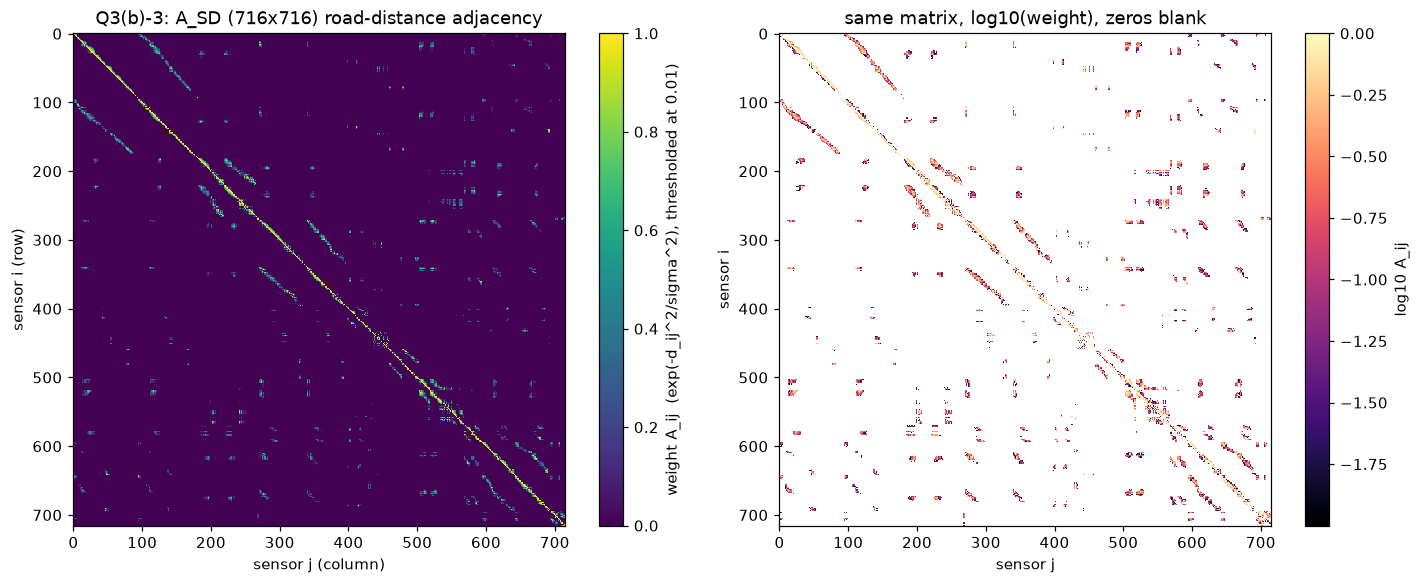

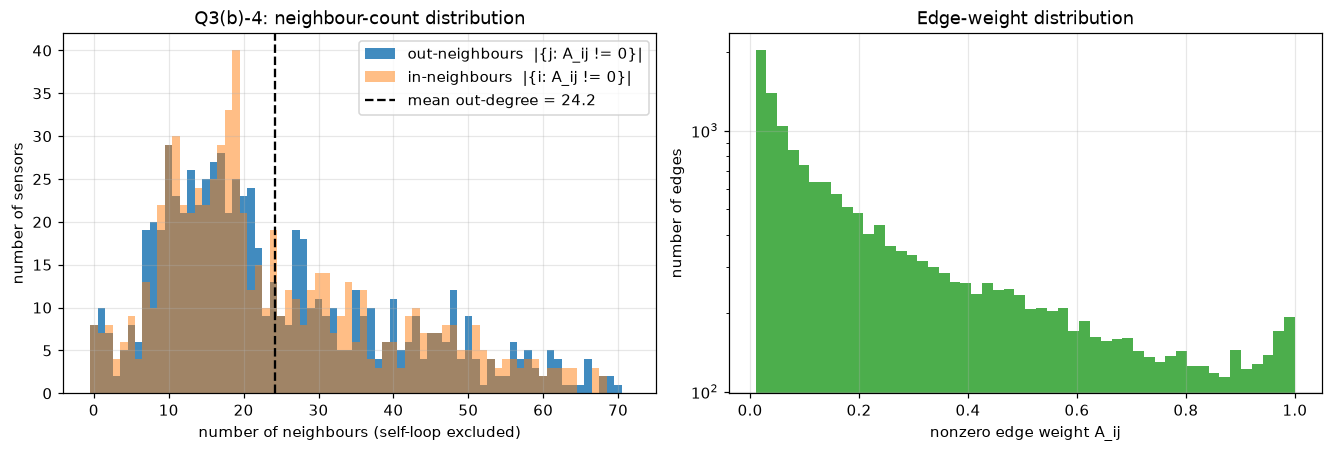

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2), constrained_layout=True)
im = ax[0].imshow(A, cmap='viridis', vmin=0, vmax=1, interpolation='nearest')
ax[0].set_title('Q3(b)-3: A_SD (716x716) road-distance adjacency'); ax[0].set_xlabel('sensor j (column)'); ax[0].set_ylabel('sensor i (row)'); ax[0].grid(False)
fig.colorbar(im, ax=ax[0], label='weight A_ij  (exp(-d_ij^2/sigma^2), thresholded at 0.01)')
im2 = ax[1].imshow(np.log10(np.where(A > 0, A, np.nan)), cmap='magma', interpolation='nearest')
ax[1].set_title('same matrix, log10(weight), zeros blank'); ax[1].set_xlabel('sensor j'); ax[1].set_ylabel('sensor i'); ax[1].grid(False)
fig.colorbar(im2, ax=ax[1], label='log10 A_ij'); fig.savefig(f'{FIG}/q3b_adjacency_heatmap.png', dpi=160); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
bins = np.arange(0, deg_out.max() + 3) - .5
ax[0].hist(deg_out, bins=bins, color='tab:blue', alpha=.85, label='out-neighbours  |{j: A_ij != 0}|'); ax[0].hist(deg_in, bins=bins, color='tab:orange', alpha=.5, label='in-neighbours  |{i: A_ij != 0}|')
ax[0].axvline(deg_out.mean(), color='k', ls='--', label=f'mean out-degree = {deg_out.mean():.1f}')
ax[0].set_xlabel('number of neighbours (self-loop excluded)'); ax[0].set_ylabel('number of sensors'); ax[0].set_title('Q3(b)-4: neighbour-count distribution'); ax[0].legend()
ax[1].hist(off[E], bins=50, color='tab:green', alpha=.85); ax[1].set_xlabel('nonzero edge weight A_ij'); ax[1].set_ylabel('number of edges'); ax[1].set_title('Edge-weight distribution'); ax[1].set_yscale('log')
fig.savefig(f'{FIG}/q3b_degree_distribution.png', dpi=160); plt.show()

### Q3(b)-5  What does a nonzero $A_{ij}$ mean?
$A_{ij}\neq0$ means sensor $j$ is *road-network-close* to sensor $i$: following the highway network (not straight-line) the distance $d_{ij}$ from $i$ to $j$ is short enough that the thresholded Gaussian kernel $A_{ij}=\exp(-d_{ij}^2/\sigma^2)$ (σ = std of all road distances, entries below $r=0.01$ set to 0) is ≥ 0.01. The value in $(0.01,1]$ is a **relationship strength**: close to 1 = very near along the road, near 0.01 = barely connected. Because road distance is *directional* (one-way carriageways: the way from $i$ to $j$ differs from $j$ to $i$) the matrix is **directed / asymmetric** — the numbers above show how many pairs differ. The stored diagonal is 1 (distance 0, a self-loop).

## Q3(c)  Graph neighbourhoods around one sensor
Definitions (row convention of the assignment): one-hop $\mathcal N(i)=\{j:A_{ij}\ne0\}$ (self excluded); two-hop = nodes reachable by a directed path of ≤ 2 edges, i.e. $\mathcal N_{\le2}(i)=\{j: ((A+I)^2)_{ij}\neq0\}$, and the *strict* two-hop ring is $\mathcal N_{\le2}\setminus(\mathcal N\cup\{i\})$. The sensor is picked deterministically: among sensors with the median out-degree, the one with the highest fraction of observed 15-min values in 2020 (ties → lowest index).

observed fraction of chosen sensor in 2020: 0.9999
chosen sensor index 33 ID 1126411 | {'Fwy': 'I5-N', 'Direction': 'N', 'Lanes': 4, 'Lat': 32.770668, 'Lng': -117.206677}


one-hop: 20 | within-two-hop: 73 | strict two-hop ring: 53

ONE-HOP neighbours of sensor 1126411
 idx sensor_id  fwy dir   A_ij   A_ji  geo_km
  34   1114805 I5-N   N 0.9527 0.0000    0.97
  35   1114035 I5-N   N 0.8244 0.0000    1.94
  36   1108547 I5-N   N 0.7583 0.0000    2.32
  37   1118707 I5-N   N 0.6343 0.0000    2.94
 129   1114806 I5-S   S 0.4603 0.0831    0.96
 128   1126426 I5-S   S 0.2639 0.1824    0.24
 130   1108711 I5-S   S 0.2039 0.0396    1.93
 131   1108693 I5-S   S 0.1236 0.0115    3.27
 185   1115356 I8-E   E 0.0824 0.5054    1.13
 127   1117818 I5-S   S 0.0591 0.5471    2.31
 186   1115413 I8-E   E 0.0497 0.1344    1.22
 184   1113486 I8-E   E 0.0420 0.4268    1.22
 181   1111514 I8-E   E 0.0392 0.4422    1.20
 126   1108615 I5-S   S 0.0387 0.2444    2.66
 223   1115517 I8-W   W 0.0363 0.7100    1.19
 187   1115432 I8-E   E 0.0261 0.2218    1.27
 222   1115528 I8-W   W 0.0216 0.8192    1.11
 125   1117871 I5-S   S 0.0203 0.0000    3.03
 221   1116574 I8-W   W 0.014

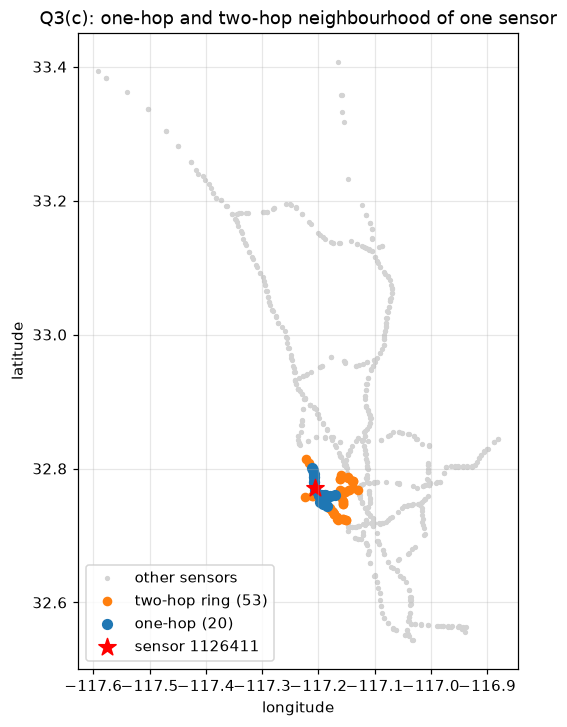

In [15]:
tr_valid = valid[segs15[0][0]:segs15[0][1]]
cands = np.where(deg_out == int(np.median(deg_out)))[0]
i0 = int(cands[np.argmax(tr_valid[:, cands].mean(0))]); print('observed fraction of chosen sensor in 2020: %.4f' % tr_valid[:, i0].mean()); print('chosen sensor index', i0, 'ID', sensor_ids[i0], '|', sd_meta.loc[i0, ['Fwy', 'Direction', 'Lanes', 'Lat', 'Lng']].to_dict())
B = (off > 0).astype(np.int64); B2 = ((B + np.eye(716, dtype=np.int64)) @ (B + np.eye(716, dtype=np.int64))) > 0
one_hop = np.where(B[i0])[0]; two_all = np.where(B2[i0])[0]; two_ring = np.array([j for j in two_all if j != i0 and j not in set(one_hop)])
print('one-hop: %d | within-two-hop: %d | strict two-hop ring: %d' % (len(one_hop), len(two_all) - 1, len(two_ring)))
tab1 = pd.DataFrame({'idx': one_hop, 'sensor_id': [sensor_ids[j] for j in one_hop], 'fwy': sd_meta.Fwy.values[one_hop], 'dir': sd_meta.Direction.values[one_hop],
                     'A_ij': A[i0, one_hop].round(4), 'A_ji': A[one_hop, i0].round(4), 'geo_km': DIST[i0, one_hop].round(2)}).sort_values('A_ij', ascending=False)
print('\nONE-HOP neighbours of sensor', sensor_ids[i0]); print(tab1.to_string(index=False))
tab2 = pd.DataFrame({'idx': two_ring, 'sensor_id': [sensor_ids[j] for j in two_ring], 'fwy': sd_meta.Fwy.values[two_ring], 'dir': sd_meta.Direction.values[two_ring],
                     'geo_km': DIST[i0, two_ring].round(2), 'via_nbr_count': [int(B[one_hop][:, j].sum()) for j in two_ring]}).sort_values('geo_km')
print('\nSTRICT TWO-HOP neighbours (reachable in exactly 2 edges, not 1) of sensor', sensor_ids[i0], '(%d, first 25 by distance)' % len(two_ring)); print(tab2.head(25).to_string(index=False))
tab1.to_csv(f'{RES}/q3c_one_hop.csv', index=False); tab2.to_csv(f'{RES}/q3c_two_hop.csv', index=False)

fig, ax = plt.subplots(figsize=(7.5, 6.5), constrained_layout=True)
ax.scatter(lng, lat, s=6, c='lightgray', label='other sensors')
ax.scatter(lng[two_ring], lat[two_ring], s=28, c='tab:orange', label=f'two-hop ring ({len(two_ring)})')
ax.scatter(lng[one_hop], lat[one_hop], s=40, c='tab:blue', label=f'one-hop ({len(one_hop)})')
ax.scatter(lng[i0], lat[i0], s=140, c='red', marker='*', label=f'sensor {sensor_ids[i0]}')
ax.set_xlabel('longitude'); ax.set_ylabel('latitude'); ax.set_title('Q3(c): one-hop and two-hop neighbourhood of one sensor'); ax.legend(); ax.set_aspect(1 / np.cos(np.deg2rad(lat.mean())))
fig.savefig(f'{FIG}/q3c_neighbourhood_map.png', dpi=160); plt.show()
R['q3c'] = dict(sensor_index=i0, sensor_id=sensor_ids[i0], one_hop=len(one_hop), within_two_hop=len(two_all) - 1, strict_two_hop=len(two_ring),
                one_hop_ids=[sensor_ids[j] for j in one_hop], two_hop_ids=[sensor_ids[j] for j in two_ring])

### Q3(c)-1  Why neighbours help — evidence from the data (training year 2020 only)
Mean Pearson correlation (15-min observations where both series are observed) between a sensor and (i) its one-hop neighbours, (ii) its strict two-hop ring, (iii) 100 random non-neighbours, averaged over all sensors. Two versions: **raw flow** (dominated by the shared daily cycle, so all correlations are high) and **residual flow** after subtracting each sensor's own mean weekly profile (mean for each weekday x 15-min slot, computed on the training year) — the residual measures *local, non-periodic co-movement* (queues, incidents, demand shocks), which is what a graph can add.

/tmp/ipykernel_102965/3293084958.py:5: RuntimeWarning: Mean of empty slice
  m_ = slot == k_; Xres[m_] = Xt[m_] - np.nanmean(Xt[m_], axis=0)


raw       sensors with defined correlations: 685 of 703 | one-hop 0.865 | two-hop ring 0.867 | random non-neighbours 0.843 | share of sensors with one-hop > random: 70.7%
residual  sensors with defined correlations: 685 of 703 | one-hop 0.734 | two-hop ring 0.728 | random non-neighbours 0.672 | share of sensors with one-hop > random: 91.7%
chosen sensor (residual): one-hop 0.854 | two-hop ring 0.851


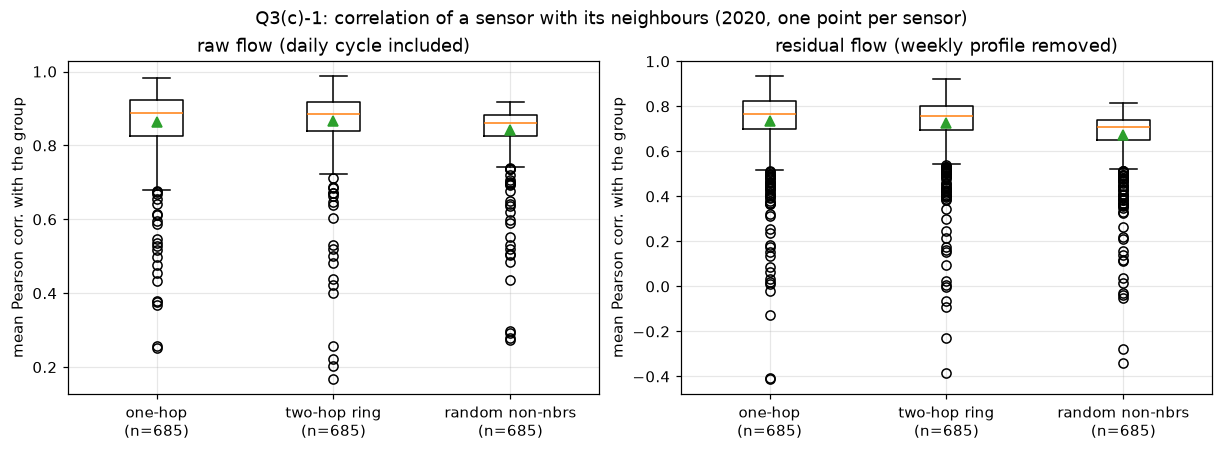

In [16]:
a, b = segs15[0]; Xt = np.where(valid[a:b], X15[a:b], np.nan); tt = ts15[a:b]
slot = tt.dayofweek.values * 96 + tt.hour.values * 4 + tt.minute.values // 15
Xres = np.full_like(Xt, np.nan)
for k_ in range(7 * 96):
    m_ = slot == k_; Xres[m_] = Xt[m_] - np.nanmean(Xt[m_], axis=0)
corr_raw = pd.DataFrame(Xt).corr(min_periods=2000).values
corr_res = pd.DataFrame(Xres).corr(min_periods=2000).values
rng = np.random.default_rng(SEED)
def group_corr(C):
    oneh, twoh, rnd = [], [], []
    for i in range(716):
        n1 = np.where(B[i])[0]; n2 = np.array([j for j in np.where(B2[i])[0] if j != i and B[i, j] == 0])
        nn_ = np.setdiff1d(np.arange(716), np.r_[i, n1, n2])
        if len(n1) and len(n2):
            oneh.append(np.nanmean(C[i, n1])); twoh.append(np.nanmean(C[i, n2])); rnd.append(np.nanmean(C[i, rng.choice(nn_, 100, replace=False)]))
    return np.array(oneh), np.array(twoh), np.array(rnd)
import warnings; warnings.filterwarnings('ignore', category=RuntimeWarning)
G_raw, G_res = group_corr(corr_raw), group_corr(corr_res)
def valid_stats(g):
    ok = ~(np.isnan(g[0]) | np.isnan(g[1]) | np.isnan(g[2]))                    # sensors for which all three correlations are defined
    return dict(n_with_both_rings=int(len(g[0])), n=int(ok.sum()), one_hop=float(g[0][ok].mean()), two_hop=float(g[1][ok].mean()), random=float(g[2][ok].mean()), frac_sensors_onehop_gt_random=float(np.mean(g[0][ok] > g[2][ok])))
CORR = {'raw': valid_stats(G_raw), 'residual': valid_stats(G_res)}
for nm, st_ in CORR.items():
    print('%-9s sensors with defined correlations: %d of %d | one-hop %.3f | two-hop ring %.3f | random non-neighbours %.3f | share of sensors with one-hop > random: %.1f%%' %
          (nm, st_['n'], st_['n_with_both_rings'], st_['one_hop'], st_['two_hop'], st_['random'], 100 * st_['frac_sensors_onehop_gt_random']))
print('chosen sensor (residual): one-hop %.3f | two-hop ring %.3f' % (np.nanmean(corr_res[i0, one_hop]), np.nanmean(corr_res[i0, two_ring])))
R['q3c_correlation'] = CORR
fig, ax = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True, sharey=False)
for a_, g, ttl in zip(ax, (G_raw, G_res), ('raw flow (daily cycle included)', 'residual flow (weekly profile removed)')):
    vals = [v[~np.isnan(v)] for v in g]                                        # sensors without data give NaN correlations -> drop them (matplotlib draws nothing for NaN)
    a_.boxplot(vals, tick_labels=[f'one-hop\n(n={len(vals[0])})', f'two-hop ring\n(n={len(vals[1])})', f'random non-nbrs\n(n={len(vals[2])})'], showmeans=True)
    a_.set_ylabel('mean Pearson corr. with the group'); a_.set_title(ttl)
fig.suptitle('Q3(c)-1: correlation of a sensor with its neighbours (2020, one point per sensor)')
fig.savefig(f'{FIG}/q3c_neighbour_correlation.png', dpi=160); plt.show()

### Q3(c)-2  One-hop vs two-hop aggregation ($\hat A$ vs $\hat A^2$) — receptive field
One GCN layer computes $H=\sigma(\hat A ZW)$: node $i$ mixes its own features with those of its **one-hop** neighbours (row $i$ of $\hat A$). Stacking two layers gives $\hat A(\hat A Z)$ = $\hat A^2Z$: row $i$ of $\hat A^2$ is non-zero on all nodes reachable in ≤2 edges, i.e. each node now also sees its **neighbours' neighbours** (receptive field grows from $|\mathcal N(i)|+1$ to $|\mathcal N_{\le2}(i)|+1$). The table below measures how fast the receptive field grows with depth $k$ on the real SD graph.

In [17]:
Ah = np.asarray(((off + np.eye(716)) / (off + np.eye(716)).sum(1, keepdims=True)), dtype=np.float64)    # row-normalised D_out^-1 (A+I), the fixed graph used later
K = 30; reach = np.eye(716, dtype=bool); rf = []
for k in range(0, K + 1):
    rf.append(reach.sum(1)); reach = (reach.astype(np.float32) @ (B + np.eye(716, dtype=np.int64)).astype(np.float32)) > 0
rf = np.array(rf)                                                           # (K+1, 716) nodes within k hops (incl. self)
print('mean receptive-field size (nodes within k hops) k=0,1,2,3,5,10,20,30:', [round(float(rf[k].mean()), 1) for k in (0, 1, 2, 3, 5, 10, 20, 30)])
print('chosen sensor: k=1 -> %d, k=2 -> %d nodes' % (rf[1, i0], rf[2, i0]))
print('A_hat row i0: nnz=%d ; (A_hat^2) row i0: nnz=%d' % (np.count_nonzero(Ah[i0]), np.count_nonzero(np.linalg.matrix_power(Ah, 2)[i0])))
assert np.count_nonzero(np.linalg.matrix_power(Ah, 2)[i0]) == rf[2, i0]

mean receptive-field size (nodes within k hops) k=0,1,2,3,5,10,20,30: [1.0, 25.2, 67.9, 117.0, 231.2, 468.8, 668.2, 687.3]
chosen sensor: k=1 -> 21, k=2 -> 74 nodes
A_hat row i0: nnz=21 ; (A_hat^2) row i0: nnz=74


### Q3(c)-3  Too many graph-convolution layers → over-smoothing (numeric demonstration)
Repeated propagation $x^{(k)}=\hat A^k x$ is a low-pass filter on the graph: the signal differences between connected nodes die out and all nodes converge toward the same (stationary-weighted) value. We measure, for a real traffic snapshot (z-scored, rush-hour 15-min step of the training year) and for a random feature vector, (a) the **standard deviation across nodes** of $\hat A^k x$ relative to $k=0$, and (b) the **Dirichlet energy** (mean squared difference along edges) relative to $k=0$.

graph components: weakly connected = 7, strongly connected = 17


std across nodes, real snapshot  k=0,1,2,4,8,16,32,40: [1.    0.728 0.663 0.595 0.516 0.448 0.411 0.404]
std across nodes, random vector  k=0,1,2,4,8,16,32,40: [1.    0.332 0.259 0.208 0.179 0.175 0.182 0.186]
Dirichlet energy, real snapshot  k=0,1,2,4,8,16,32,40: [1.     0.1406 0.0725 0.0381 0.0191 0.0082 0.0048 0.0044]


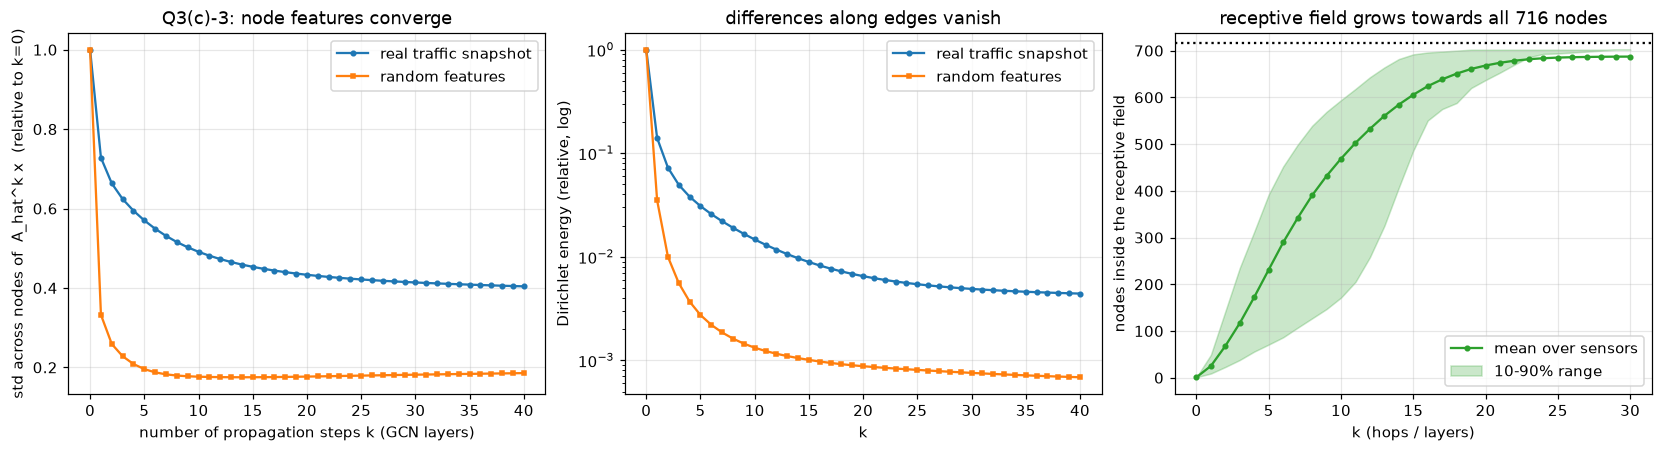

per-layer message-passing cost with d=32: dense 32.8 MFLOP vs sparse 1.15 MFLOP


In [18]:
t_rush = int(np.where((ts15 == pd.Timestamp('2020-02-05 08:00')))[0][0])
x_real = filled[t_rush]; x_real = (x_real - x_real.mean()) / x_real.std()
x_rand = np.random.default_rng(SEED).normal(size=716)
iu, ju = np.where(E)
import scipy.sparse as sps, scipy.sparse.csgraph as csg
n_weak, _ = csg.connected_components(sps.csr_matrix(E), directed=False); n_strong, _ = csg.connected_components(sps.csr_matrix(E), directed=True, connection='strong')
print('graph components: weakly connected = %d, strongly connected = %d' % (n_weak, n_strong))
def stats(x0):
    out = []; x = x0.copy()
    for k in range(0, 41):
        out.append((x.std(), np.mean((x[iu] - x[ju])**2))); x = Ah @ x
    out = np.array(out); return out[:, 0] / out[0, 0], out[:, 1] / out[0, 1]
sd_real, de_real = stats(x_real); sd_rand, de_rand = stats(x_rand)
print('std across nodes, real snapshot  k=0,1,2,4,8,16,32,40:', np.round(sd_real[[0, 1, 2, 4, 8, 16, 32, 40]], 3))
print('std across nodes, random vector  k=0,1,2,4,8,16,32,40:', np.round(sd_rand[[0, 1, 2, 4, 8, 16, 32, 40]], 3))
print('Dirichlet energy, real snapshot  k=0,1,2,4,8,16,32,40:', np.round(de_real[[0, 1, 2, 4, 8, 16, 32, 40]], 4))
fig, ax = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
ks = np.arange(41)
ax[0].plot(ks, sd_real, 'o-', ms=3, label='real traffic snapshot'); ax[0].plot(ks, sd_rand, 's-', ms=3, label='random features'); ax[0].set_xlabel('number of propagation steps k (GCN layers)'); ax[0].set_ylabel('std across nodes of  A_hat^k x  (relative to k=0)'); ax[0].set_title('Q3(c)-3: node features converge'); ax[0].legend()
ax[1].semilogy(ks, de_real, 'o-', ms=3, label='real traffic snapshot'); ax[1].semilogy(ks, de_rand, 's-', ms=3, label='random features'); ax[1].set_xlabel('k'); ax[1].set_ylabel('Dirichlet energy (relative, log)'); ax[1].set_title('differences along edges vanish'); ax[1].legend()
ax[2].plot(np.arange(K + 1), rf.mean(1), 'o-', ms=3, color='tab:green', label='mean over sensors'); ax[2].fill_between(np.arange(K + 1), np.quantile(rf, .1, axis=1), np.quantile(rf, .9, axis=1), alpha=.25, color='tab:green', label='10-90% range')
ax[2].axhline(716, color='k', ls=':'); ax[2].set_xlabel('k (hops / layers)'); ax[2].set_ylabel('nodes inside the receptive field'); ax[2].set_title('receptive field grows towards all 716 nodes'); ax[2].legend()
fig.savefig(f'{FIG}/q3c_oversmoothing.png', dpi=160); plt.show()
# compute cost per layer
nnz_hat = int(np.count_nonzero(Ah))
R['q3c_oversmoothing'] = dict(weak_components=int(n_weak), strong_components=int(n_strong), std_ratio_real={str(k): float(sd_real[k]) for k in (0, 1, 2, 4, 8, 16, 32, 40)}, std_ratio_random={str(k): float(sd_rand[k]) for k in (0, 1, 2, 4, 8, 16, 32, 40)},
                              dirichlet_real={str(k): float(de_real[k]) for k in (0, 1, 2, 4, 8, 16, 32, 40)},
                              receptive_field_mean={str(k): float(rf[k].mean()) for k in (0, 1, 2, 3, 5, 10, 20, 30)},
                              nnz_Ahat=nnz_hat, dense_cost_per_layer_flops=int(2 * 716 * 716 * 32), sparse_cost_per_layer_flops=int(2 * nnz_hat * 32))
print('per-layer message-passing cost with d=32: dense %.1f MFLOP vs sparse %.2f MFLOP' % (2*716*716*32/1e6, 2*nnz_hat*32/1e6))

**Answers to the three Q3(c) questions.**

**(1) Why do neighbouring sensors help?** Congestion is a spatial process: a queue that forms downstream grows back upstream along the road, and neighbouring sensors share demand (the same commuters), capacity, weather and incidents; averaging neighbours also reduces sensor noise and can stand in for a sensor that is temporarily missing. The data support this, *but modestly*: raw 15-min flows are highly correlated for every pair of sensors in the county because of the shared daily cycle (one-hop 0.865 vs random 0.843, numbers printed above), so the useful signal is in the residual after removing each sensor's weekly profile — there one-hop neighbours (0.734) are clearly more correlated than random sensors (0.672), and the two-hop ring (0.728) is almost as informative as the one-hop ring. We therefore expect a graph to help, but not to change the forecast dramatically when each sensor already has 2 h of its own history.

**(2) One-hop vs two-hop aggregation.** One layer with $\hat A$ gives each node a weighted average over itself and its one-hop neighbours (the receptive field is the row support of $\hat A$: 21 nodes for the chosen sensor, including itself). Two layers give $\hat A^2$: row $i$ is non-zero on every node reachable in ≤ 2 edges (74 nodes for the chosen sensor), i.e. each node now also sees its neighbours' neighbours, with weights that are products of one-hop weights and therefore decay with graph distance. The mean receptive field grows from 25 (k=1) to 68 (k=2), 117 (k=3) and 469 (k=10) nodes. Two hops capture slower, larger-scale propagation (a queue that spreads over several sensors in 15–60 minutes) at the cost of mixing in sensors that are less relevant.

**(3) Can too many GCN layers hurt? Yes.** (i) **Over-smoothing:** every propagation step is a low-pass filter; stacking layers makes node representations converge. In the experiment above the Dirichlet energy (squared differences between *connected* sensors) of a real traffic snapshot falls to 0.4 % of its initial value after 40 propagations, so connected sensors become indistinguishable. The across-node standard deviation falls by ~60 % and then flattens rather than reaching 0, because the directed road graph has several separate components that each converge to their own level instead of a single global value. (ii) **Over-squashing / bottleneck:** the receptive field grows fast (≈ 469 of 716 nodes after 10 hops), so information from hundreds of sensors must be squeezed into one $d$-dimensional vector ($d \in [16,32]$ here). (iii) **Noise:** distant sensors are largely irrelevant for a one-hour forecast and add variance. (iv) **Cost/optimisation:** each layer adds a graph multiplication ($\approx 33$ MFLOP dense or $\approx 1.2$ MFLOP sparse per sample for $d=32$, printed above) plus parameters, and deeper stacks are harder to train and over-fit. This is why traffic models use shallow graph convolutions (here one layer) combined with temporal modelling.

In [19]:
save_json(R, f'{RES}/q3_results.json'); print('saved results/q3_results.json'); print(sorted(os.listdir(PROC)))

saved results/q3_results.json
['sd_adj.npy', 'sd_dist_km.npy', 'sd_flow_15min_filled.npy', 'sd_flow_15min_raw.npy', 'sd_meta.csv', 'sd_raw_5min_2020.npy', 'sd_raw_5min_2020_ts.npy', 'sd_raw_5min_2021.npy', 'sd_raw_5min_2021_ts.npy', 'sd_sensor_ids.npy', 'sd_timestamps.npy', 'sd_valid_mask.npy']
